In [10]:

import pandas as pd
import numpy as np
from google.colab import files
uploaded = files.upload()
df_transformed = pd.read_csv("employee_attriton_data_clean.csv")

Saving employee_attriton_data_clean.csv to employee_attriton_data_clean (1).csv


# **Creating new features**

In [11]:
df_transformed['TenureCategory'] = pd.cut(
    df_transformed['TenureYears'],
    bins=[-1, 2, 5, float('inf')],
    labels=['Short-term', 'Medium-term', 'Long-term']
)

In [12]:
print(df_transformed['MonthlySalary'].describe())

count    49000.000000
mean      5999.236893
std       1957.551040
min          0.290000
25%       4675.982500
50%       5998.370000
75%       7310.862500
max      15168.700000
Name: MonthlySalary, dtype: float64


In [13]:
df_transformed['SalaryBand'] = pd.qcut(
    df_transformed['MonthlySalary'],
    q=3,
    labels=['Low', 'Medium', 'High']
)

In [14]:
print(df_transformed['SalaryBand'].value_counts())

SalaryBand
High      16334
Low       16333
Medium    16333
Name: count, dtype: int64


In [15]:
print(
    df_transformed.groupby('SalaryBand', observed=True)['MonthlySalary']
    .agg(['min', 'max', 'mean', 'count'])
)

                min       max         mean  count
SalaryBand                                       
Low            0.29   5183.37  3863.633417  16333
Medium      5183.66   6806.02  5998.006566  16333
High        6806.26  15168.70  8135.939874  16334


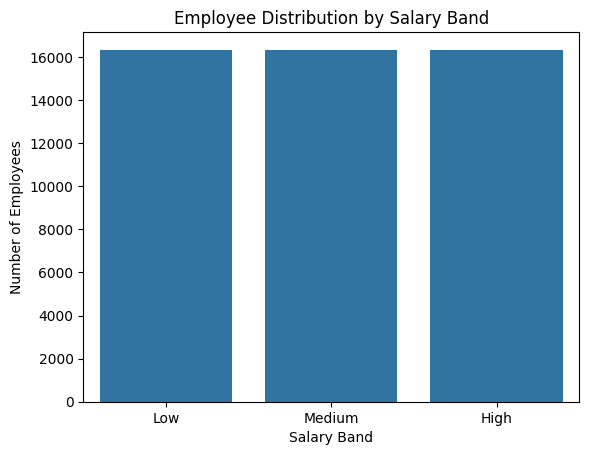

In [16]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.countplot(data=df_transformed, x='SalaryBand',
              order=['Low', 'Medium', 'High'])

plt.title('Employee Distribution by Salary Band')
plt.xlabel('Salary Band')
plt.ylabel('Number of Employees')
plt.show()

In [17]:
df_transformed['AgeGroup'] = pd.cut(
    df_transformed['Age'],
    bins=[0, 24, 34, 44, 54, float('inf')],
    labels=['Young', 'Early Career', 'Mid Career',
            'Experienced', 'Senior']
)

In [18]:
df_transformed['SalaryToTenureRatio'] = (
    df_transformed['MonthlySalary'] /
    (df_transformed['TenureYears'] + 1)
)

# **Encode categorical variables**

In [19]:
df_transformed.select_dtypes(include=['object', 'category']).columns

Index(['Gender', 'JobRole', 'Attrition', 'TenureCategory', 'SalaryBand',
       'AgeGroup'],
      dtype='object')

In [21]:
df_transformed = pd.get_dummies(
    df_transformed,
    columns=[
        'Gender',
        'JobRole',
        'TenureCategory',
        'SalaryBand',
        'AgeGroup',
    ],
    dtype=int
)

In [22]:
df_transformed['Attrition'] = df_transformed['Attrition'].map({
    'No': 0,
    'Yes': 1
})

In [23]:
print(df_transformed.head())

   EmployeeID   Age  TenureYears  PerformanceRating  MonthlySalary  Attrition  \
0       23056  33.0          1.0                1.0        9734.51          0   
1       47703  33.0          5.0                4.0        7552.38          0   
2        7424  45.0          0.0                4.0        3931.63          0   
3       34697  35.0          2.0                3.0        7992.26          0   
4       31490  42.0          1.0                3.0        5215.60          1   

   SalaryToTenureRatio  Gender_Female  Gender_Male  Gender_Non-Binary  ...  \
0          4867.255000              1            0                  0  ...   
1          1258.730000              1            0                  0  ...   
2          3931.630000              0            1                  0  ...   
3          2664.086667              0            0                  1  ...   
4          2607.800000              0            1                  0  ...   

   TenureCategory_Medium-term  TenureCategor

In [24]:
print(df_transformed.dtypes)

EmployeeID                      int64
Age                           float64
TenureYears                   float64
PerformanceRating             float64
MonthlySalary                 float64
Attrition                       int64
SalaryToTenureRatio           float64
Gender_Female                   int64
Gender_Male                     int64
Gender_Non-Binary               int64
JobRole_Data Analyst            int64
JobRole_HR Specialist           int64
JobRole_Manager                 int64
JobRole_Sales Exec              int64
JobRole_Software Engineer       int64
TenureCategory_Short-term       int64
TenureCategory_Medium-term      int64
TenureCategory_Long-term        int64
SalaryBand_Low                  int64
SalaryBand_Medium               int64
SalaryBand_High                 int64
AgeGroup_Young                  int64
AgeGroup_Early Career           int64
AgeGroup_Mid Career             int64
AgeGroup_Experienced            int64
AgeGroup_Senior                 int64
dtype: objec

In [25]:
print(df_transformed.select_dtypes(
    include=['object', 'category']
).columns)

Index([], dtype='object')


# **Check results**

In [26]:
display(df_transformed.head(10))

,EmployeeID,Age,TenureYears,PerformanceRating,MonthlySalary,Attrition,SalaryToTenureRatio,Gender_Female,Gender_Male,Gender_Non-Binary,...,TenureCategory_Medium-term,TenureCategory_Long-term,SalaryBand_Low,SalaryBand_Medium,SalaryBand_High,AgeGroup_Young,AgeGroup_Early Career,AgeGroup_Mid Career,AgeGroup_Experienced,AgeGroup_Senior
0,23056,33.0,1.0,1.0,9734.51,0,4867.255000,1,0,0,...,0,0,0,0,1,0,1,0,0,0
1,47703,33.0,5.0,4.0,7552.38,0,1258.730000,1,0,0,...,1,0,0,0,1,0,1,0,0,0
2,7424,45.0,0.0,4.0,3931.63,0,3931.630000,0,1,0,...,0,0,1,0,0,0,0,0,1,0
3,34697,35.0,2.0,3.0,7992.26,0,2664.086667,0,0,1,...,0,0,0,0,1,0,0,1,0,0
4,31490,42.0,1.0,3.0,5215.60,1,2607.800000,0,1,0,...,0,0,0,1,0,0,0,1,0,0
5,3501,46.0,8.0,4.0,1813.52,0,201.502222,0,1,0,...,0,1,1,0,0,0,0,0,1,0
6,476,32.0,2.0,3.0,6715.74,0,2238.580000,1,0,0,...,0,0,0,1,0,0,1,0,0,0
7,23345,29.0,1.0,2.0,5614.47,0,2807.235000,1,0,0,...,0,0,0,1,0,0,1,0,0,0
8,12126,28.0,3.0,3.0,5154.96,0,1288.740000,1,0,0,...,1,0,1,0,0,0,1,0,0,0
9,43685,30.0,0.0,1.0,3758.98,0,3758.980000,0,1,0,...,0,0,1,0,0,0,1,0,0,0


In [27]:
print("Dataset shape:", df_transformed.shape)

Dataset shape: (49000, 26)


In [28]:
print(df_transformed.dtypes)

EmployeeID                      int64
Age                           float64
TenureYears                   float64
PerformanceRating             float64
MonthlySalary                 float64
Attrition                       int64
SalaryToTenureRatio           float64
Gender_Female                   int64
Gender_Male                     int64
Gender_Non-Binary               int64
JobRole_Data Analyst            int64
JobRole_HR Specialist           int64
JobRole_Manager                 int64
JobRole_Sales Exec              int64
JobRole_Software Engineer       int64
TenureCategory_Short-term       int64
TenureCategory_Medium-term      int64
TenureCategory_Long-term        int64
SalaryBand_Low                  int64
SalaryBand_Medium               int64
SalaryBand_High                 int64
AgeGroup_Young                  int64
AgeGroup_Early Career           int64
AgeGroup_Mid Career             int64
AgeGroup_Experienced            int64
AgeGroup_Senior                 int64
dtype: objec

In [29]:
print(df_transformed.select_dtypes(
    include=['object', 'category']
).columns)

Index([], dtype='object')


In [30]:
print(df_transformed['Attrition'].value_counts())

Attrition
0    36470
1    12530
Name: count, dtype: int64


In [31]:
print(df_transformed.isnull().sum())

EmployeeID                    0
Age                           0
TenureYears                   0
PerformanceRating             0
MonthlySalary                 0
Attrition                     0
SalaryToTenureRatio           0
Gender_Female                 0
Gender_Male                   0
Gender_Non-Binary             0
JobRole_Data Analyst          0
JobRole_HR Specialist         0
JobRole_Manager               0
JobRole_Sales Exec            0
JobRole_Software Engineer     0
TenureCategory_Short-term     0
TenureCategory_Medium-term    0
TenureCategory_Long-term      0
SalaryBand_Low                0
SalaryBand_Medium             0
SalaryBand_High               0
AgeGroup_Young                0
AgeGroup_Early Career         0
AgeGroup_Mid Career           0
AgeGroup_Experienced          0
AgeGroup_Senior               0
dtype: int64


In [32]:
df_transformed.to_csv(
    'transformed_hr_dataset.csv',
    index=False
)

In [33]:
from google.colab import files

files.download('transformed_hr_dataset.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>